# SImulations

In this notebook we simulate experiments to prove the efficacy of the Softmin Energy minimization method over other established global optimization methods.
The Softmin energy is defined as 
$$
    J_\beta(\mathbf{x}) = \sum_{i=1}^n \frac{e^{-\beta f (x_i)}f(x_i)}{\sum_{j=1}^n e^{-\beta f(x_j)}}
$$
with $\beta>0$, $\mathbf{x} = (x_1,\dots,x_n)$.

## Imports and utility functions

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle as pkl

from tqdm import tqdm
from simulations import *
from potentials import *
from viz import plot_entry_time_comparison, plot_value_comparison, plot_prefactor_dynamics
import multiprocessing as mp

plt.rcParams['font.size'] = 15
#uncomment to double the fontsize in plots

N_CPU = mp.cpu_count()


## Exit time from the maximizing regime

### Plot

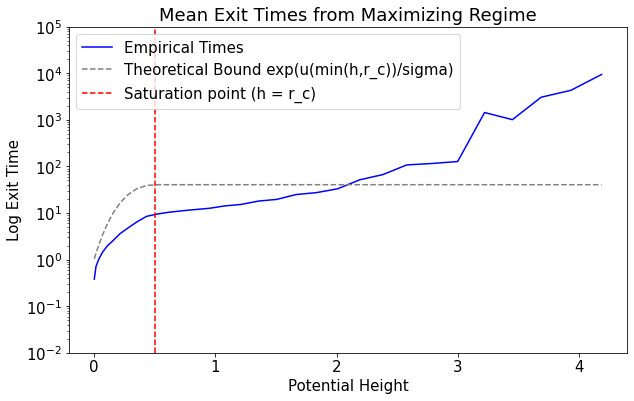

In [2]:
from scipy.optimize import brentq

noise = 0.05
beta = 2
n_particles = 100
tilt = 0.05  # matches TILT in run_theory_verification.py

def u(r, beta, n=n_particles):
    """Reduced potential along the frozen-background channel (Theorem 3.1, revised theory)."""
    return n * r * np.exp(-beta * r) / (n - 1 + np.exp(-beta * r))

def solve_r_c(beta, n=n_particles):
    """r_c = argmax u(r) = unique positive root of q(r) = (n-1)(1-beta*r) + exp(-beta*r)."""
    q = lambda r: (n - 1) * (1 - beta * r) + np.exp(-beta * r)
    return brentq(q, 1e-9, 50 / beta)

# beta and n are fixed for this whole sweep, so r_c is a single constant: the bound u(min(h, r_c))
# saturates once the physical barrier h exceeds r_c (Remark: "barrier saturates rather than
# growing with h").
r_c = solve_r_c(beta)

mean_exit_times, theory_bounds, x = [], [], []
q1_exit_times, q3_exit_times, std_exit_times = [], [], []

for delta in np.arange(0.25, 4.25, 0.125):
    # NOTE: kwargs here uses the (new) asymmetric_double_well to compute h consistently with
    # Theorem 3.1's setup; the loaded exit_times below still come from the pre-revision,
    # symmetric-well sweep and need to be regenerated (via a cluster rerun of
    # run_theory_verification.py) before this overlay is a genuine apples-to-apples check.
    kwargs = asymmetric_double_well(delta, tilt)
    h = float(kwargs['f_vec']([kwargs['saddle']]) - kwargs['f_vec']([kwargs['z_start']]))
    if delta.is_integer(): delta = int(delta)
    string = f"softmin_static_double_well_init0_{delta}_{noise}".replace('.','p')+".pkl"
    with open(f"results/{string}", "rb") as f:
        exit_times = pkl.load(f)

    x.append(h)
    mean_exit_times.append(np.mean(exit_times))
    theory_bounds.append(np.exp(u(min(h, r_c), beta) / noise))

    std_exit_times.append(np.std(exit_times))
    q1_exit_times.append(np.percentile(exit_times, 25))
    q3_exit_times.append(np.percentile(exit_times, 75))

def get_asymmetric_errorbars(mean, q1, q3):
    lower = np.array(mean) - np.array(q1)
    upper = np.array(q3) - np.array(mean)
    return [np.maximum(lower, 0), np.maximum(upper, 0)]


fig, ax = plt.subplots(figsize=(10, 6))
err_exit_times = get_asymmetric_errorbars(mean_exit_times, q1_exit_times, q3_exit_times)
ax.plot(x, mean_exit_times, label='Empirical Times', color='blue')
ax.plot(x, theory_bounds, label='Theoretical Bound exp(u(min(h,r_c))/sigma)', color='gray', linestyle='--')
ax.vlines([r_c], ymin=1e-2, ymax=1e5, colors='red', linestyles='dashed', label='Saturation point (h = r_c)')
ax.set_yscale('log')
ax.set_ylim(1e-2, 1e5)
ax.set_xlabel('Potential Height')
ax.set_ylabel('Log Exit Time')
ax.set_title('Mean Exit Times from Maximizing Regime')
ax.legend()


## 1 Dimensional Double Well Potential

### Plots

In [ ]:
x = []
for delta in range(1, 31):
    kwargs = one_dimensional_double_well(delta)
    x.append(kwargs['critical_points'][2] - kwargs['critical_points'][0])

# SoftMin Decay dropped from the sweep (2026-08-05): a direct escape-time comparison found a
# properly-tuned fixed beta consistently faster than both decaying and increasing schedules,
# with the gap widening at harder barriers -- see Remark rem:higher-dim in the paper and the
# single-example comparison reported there instead of a full re-run of this (now redundant,
# 2x compute) series.
series = [
    {'label': 'SoftMin', 'filename_template': 'softmin_double_well_{p}.pkl',
     'color': '#0072B2', 'marker': 'o'},
    {'label': 'Simulated Annealing', 'filename_template': 'sa_double_well_{p}.pkl',
     'color': '#E69F00', 'marker': 's'},
    {'label': 'CBO', 'filename_template': 'cbo_double_well_{p}.pkl',
     'color': '#009E73', 'marker': '^', 'mask_below': 1e4},
    {'label': 'PSO', 'filename_template': 'pso_double_well_{p}.pkl',
     'color': '#D55E00', 'marker': 'D'},
    # The following series need a rerun of run_experiments_resumable.py on the cluster before
    # their .pkl files exist (they're new: CBO/PSO's noise floor was removed, and CBO Annealed /
    # Standard CBO / Standard PSO are new baselines added for the reviewer-requested fairness
    # and gradient-free comparisons). Uncomment once results/*.pkl are regenerated.
    # {'label': 'CBO Annealed', 'filename_template': 'cbo_annealed_double_well_{p}.pkl',
    #  'color': '#56B4E9', 'marker': 'v', 'mask_below': 1e4},
    # {'label': 'Standard CBO', 'filename_template': 'standard_cbo_double_well_{p}.pkl',
    #  'color': '#CC79A7', 'marker': 'P', 'mask_below': 1e4},
    # {'label': 'Standard PSO', 'filename_template': 'standard_pso_double_well_{p}.pkl',
    #  'color': '#999999', 'marker': 'X'},
]

fig, ax = plot_entry_time_comparison(
    x=x, results_dir='results', series=series, params=range(1, 31),
    xlabel='Potential Barrier Height', title='Mean Entry Time vs Potential', grid=True,
)
plt.show()


## 2 Dimensional Quadruple Well Potential

In [ ]:
x_ = []
for A in range(2, 31):
    kwargs = unbalanced_quadruple_well_setting(A, -1)
    array_values = np.sort(np.array([np.float_(kwargs['f_vec'](point)) for point in kwargs['critical_points']]))
    x_.append(array_values[4] - array_values[3])

# SoftMin Decay dropped from the sweep (2026-08-05) -- see the note in the double-well cell above.
series = [
    {'label': 'SoftMin', 'filename_template': 'softmin_highermaxsteps_quadruple_well_{p}.pkl',
     'color': '#0072B2', 'marker': 'o'},
    {'label': 'Simulated Annealing', 'filename_template': 'sa_highermaxsteps_quadruple_well_{p}.pkl',
     'color': '#E69F00', 'marker': 's'},
    # CBO/PSO results also exist (cbo_quadruple_well_{p}.pkl, pso_quadruple_well_{p}.pkl) but
    # are excluded from this figure, matching the original notebook.
]

fig, ax = plot_entry_time_comparison(
    x=x_, results_dir='results', series=series, params=range(2, 31),
    xlabel='Potential Barrier Height', title='Mean Entry Time vs Potential', grid=True,
)
plt.show()


## Hgh Dimensional Ackley Function

In [ ]:
x = list(range(10, 100, 10))

series = [
    {'label': 'SoftMin', 'filename_template': 'SoftMin_ackley_function_dim{p}.pkl',
     'color': '#0072B2', 'marker': 'o', 'mask_below': 1e5},
    {'label': 'CBO', 'filename_template': 'CBO_ackley_function_dim{p}.pkl',
     'color': '#009E73', 'marker': '^', 'mask_below': 1e5},
    {'label': 'PSO', 'filename_template': 'PSO_ackley_function_dim{p}.pkl',
     'color': '#D55E00', 'marker': 'D', 'mask_below': 1e5},
    # SimulatedAnnealing_ackley_function_dim{p}.pkl also exists but is excluded from this
    # figure, matching the original notebook.
    # The following need a rerun of run_ackley_dimensions.py on the cluster first (see the note
    # in the double-well comparison cell above for why).
    # {'label': 'CBO Annealed', 'filename_template': 'CBO_annealed_ackley_function_dim{p}.pkl',
    #  'color': '#56B4E9', 'marker': 'v', 'mask_below': 1e5},
    # {'label': 'Standard CBO', 'filename_template': 'StandardCBO_ackley_function_dim{p}.pkl',
    #  'color': '#CC79A7', 'marker': 'P', 'mask_below': 1e5},
    # {'label': 'Standard PSO', 'filename_template': 'StandardPSO_ackley_function_dim{p}.pkl',
    #  'color': '#999999', 'marker': 'X', 'mask_below': 1e5},
]

fig, ax = plot_entry_time_comparison(
    x=x, results_dir='results', series=series,
    xlabel='Dimension', title='Mean Entry Time vs Dimension for Ackley Function', grid=True,
)
plt.show()


## Lennard-Jones Cluster Minimization

Real-physics, exact-gradient, NP-hard global-optimization benchmark (d=39..225, beyond the Ackley range above). Global minima are literature constants from the Cambridge Cluster Database (Wales & Doye 1997), `potentials.LJ_GLOBAL_MINIMA`. N=38 is the canonical hard double-funnel case (icosahedral local funnel vs. the true fcc-truncated-octahedron global minimum) -- see the driver's verification notes. Each algorithm's `first_value_time` hit time and the L-BFGS-B-quenched energy of its best configuration are both reported (see `run_lennard_jones.py`).

In [ ]:
x = [13, 38, 55, 75]

series = [
    {'label': 'SoftMin', 'filename_template': 'softmin_t_lennard_jones_n{p}.pkl',
     'color': '#0072B2', 'marker': 'o', 'mask_below': 1e5},
    {'label': 'SoftMin Decay', 'filename_template': 'softmin_decay_t_lennard_jones_n{p}.pkl',
     'color': '#F0E442', 'marker': 'd', 'mask_below': 1e5},
    {'label': 'Simulated Annealing', 'filename_template': 'sa_t_lennard_jones_n{p}.pkl',
     'color': '#E69F00', 'marker': 's', 'mask_below': 1e5},
    {'label': 'CBO', 'filename_template': 'cbo_t_lennard_jones_n{p}.pkl',
     'color': '#009E73', 'marker': '^', 'mask_below': 1e5},
    {'label': 'CBO Annealed', 'filename_template': 'cbo_annealed_t_lennard_jones_n{p}.pkl',
     'color': '#56B4E9', 'marker': 'v', 'mask_below': 1e5},
    {'label': 'PSO', 'filename_template': 'pso_t_lennard_jones_n{p}.pkl',
     'color': '#D55E00', 'marker': 'D', 'mask_below': 1e5},
    {'label': 'Standard CBO', 'filename_template': 'standard_cbo_t_lennard_jones_n{p}.pkl',
     'color': '#CC79A7', 'marker': 'P', 'mask_below': 1e5},
    {'label': 'Standard PSO', 'filename_template': 'standard_pso_t_lennard_jones_n{p}.pkl',
     'color': '#999999', 'marker': 'X', 'mask_below': 1e5},
]

fig, ax = plot_entry_time_comparison(
    x=x, results_dir='results', series=series,
    xlabel='Number of Atoms (N)', title='Mean First-Value Hit Time vs Cluster Size (Lennard-Jones)',
    grid=True,
)
plt.show()

In [ ]:
x = [13, 38, 55, 75]

series = [
    {'label': 'SoftMin', 'filename_template': 'softmin_e_lennard_jones_n{p}.pkl',
     'color': '#0072B2', 'marker': 'o'},
    {'label': 'SoftMin Decay', 'filename_template': 'softmin_decay_e_lennard_jones_n{p}.pkl',
     'color': '#F0E442', 'marker': 'd'},
    {'label': 'Simulated Annealing', 'filename_template': 'sa_e_lennard_jones_n{p}.pkl',
     'color': '#E69F00', 'marker': 's'},
    {'label': 'CBO', 'filename_template': 'cbo_e_lennard_jones_n{p}.pkl',
     'color': '#009E73', 'marker': '^'},
    {'label': 'CBO Annealed', 'filename_template': 'cbo_annealed_e_lennard_jones_n{p}.pkl',
     'color': '#56B4E9', 'marker': 'v'},
    {'label': 'PSO', 'filename_template': 'pso_e_lennard_jones_n{p}.pkl',
     'color': '#D55E00', 'marker': 'D'},
    {'label': 'Standard CBO', 'filename_template': 'standard_cbo_e_lennard_jones_n{p}.pkl',
     'color': '#CC79A7', 'marker': 'P'},
    {'label': 'Standard PSO', 'filename_template': 'standard_pso_e_lennard_jones_n{p}.pkl',
     'color': '#999999', 'marker': 'X'},
]

# Subtract the literature global minimum (keyed by N) so the y-axis is a gap above the true
# optimum, comparable across cluster sizes -- not a raw (very negative) energy.
fig, ax = plot_value_comparison(
    x=x, results_dir='results', series=series,
    xlabel='Number of Atoms (N)', ylabel='Quenched Energy Gap above Global Minimum',
    title='Quenched Energy Gap vs Cluster Size (Lennard-Jones)', grid=True,
    value_transform=lambda values, p: values - LJ_GLOBAL_MINIMA[p],
)
plt.show()

## Computational Cost Comparison

Evaluation-count-based cost comparison (gradient/objective oracle calls), per the reviewers' request for cost-matched comparisons rather than raw per-iteration counts. Fully local -- no cluster run needed.

In [3]:
import time

def measure_cost(cls, kwargs, n_steps=2000, seed=0):
    setting = unbalanced_quadruple_well_setting(5, -1)
    np.random.seed(seed)
    instance = cls(f=setting['f_vec'], df=setting['f_grad_vec'],
                   particle_init=setting['particle_init'], bounds=setting['bounds'], **kwargs)
    start = time.perf_counter()
    instance.run(n_steps)
    elapsed = time.perf_counter() - start
    return instance.n_gradient_evals, instance.n_objective_evals, elapsed

cost_configs = [
    ("SoftMin", SoftminEnergyAdagrad, dict(n=100, d=2, initial_lr=0.01, adaptive_lr=False,
                                            noise_intensity=1.0, beta=10.0, noise="normal")),
    ("Langevin", GaussianDiffusion, dict(n=100, d=2, noise=1.0, learning_rate=0.01)),
    ("Simulated Annealing", SimulatedAnnealing, dict(n=100, d=2, noise=1.0, learning_rate=0.01,
                                                       cooling_rate=0.9999, initial_temperature=10.0)),
    ("Gradient-Aware CBO", GradientAwareCBO, dict(n=100, d=2, learning_rate=0.01, consensus_rate=1.0,
                                                    noise_intensity=np.sqrt(2), beta=10.0)),
    ("Gradient-Enhanced PSO", GradientAwarePSO, dict(n=100, d=2, learning_rate=0.01, w=0.729,
                                                       c1=1.49445, c2=1.49445)),
    ("Standard CBO", CBO, dict(n=100, d=2, learning_rate=0.01, consensus_rate=1.0,
                                noise_intensity=1.0, beta=10.0)),
    ("Standard PSO", PSO, dict(n=100, d=2, learning_rate=0.01, w=0.729, c1=1.49445, c2=1.49445)),
]

rows = []
for label, cls, kwargs in cost_configs:
    grad_evals, obj_evals, wall_time = measure_cost(cls, kwargs)
    rows.append((label, grad_evals, obj_evals, wall_time))

cost_df = pd.DataFrame(rows, columns=['Method', 'Gradient Evaluations', 'Objective Evaluations',
                                        'Wall-clock Time (s)'])
cost_df


2026-07-31 14:16:43 [INFO] Initialized Simulation '' with 100 particles in 2D space.
2026-07-31 14:16:46 [INFO] Initialized Simulation '' with 100 particles in 2D space.
2026-07-31 14:16:46 [INFO] Running simulation for 2000 steps...
2026-07-31 14:16:48 [INFO] Simulation completed.
2026-07-31 14:16:48 [INFO] Initialized Simulation '' with 100 particles in 2D space.
2026-07-31 14:16:48 [INFO] Running simulation for 2000 steps...
2026-07-31 14:16:50 [INFO] Simulation completed.
2026-07-31 14:16:50 [INFO] Initialized Simulation 'GradientAwareCBO' with 100 particles in 2D space.
2026-07-31 14:16:50 [INFO] Running simulation for 2000 steps...
2026-07-31 14:16:52 [INFO] Simulation completed.
2026-07-31 14:16:52 [INFO] Initialized Simulation 'GradientAwarePSO' with 100 particles in 2D space.
2026-07-31 14:16:52 [INFO] Running simulation for 2000 steps...
2026-07-31 14:16:54 [INFO] Simulation completed.
2026-07-31 14:16:54 [INFO] Initialized Simulation 'CBO' with 100 particles in 2D space.
202

,Method,Gradient Evaluations,Objective Evaluations,Wall-clock Time (s)
0,SoftMin,2000,2000,2.223433
1,Langevin,2000,2000,1.996433
2,Simulated Annealing,2000,2000,1.856688
3,Gradient-Aware CBO,2000,2000,2.178378
4,Gradient-Enhanced PSO,2000,2000,1.876043
5,Standard CBO,0,2000,1.211824
6,Standard PSO,0,2000,0.996610


## Ascent-Descent Dynamics

Illustrates the sign-changing effective learning rate $A_{t,k}$ (Section 2): particles below the Softmin threshold descend ($A_{t,k}>0$), particles above it ascend/explore ($A_{t,k}<0$). Fully local -- a short single-seed run, no cluster dependency.

2026-07-31 14:17:29 [INFO] Initialized Simulation '' with 20 particles in 1D space.


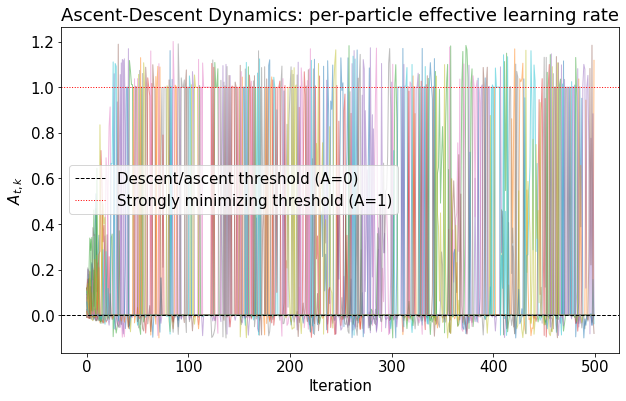

In [4]:
np.random.seed(0)
setting = one_dimensional_double_well(4)
demo_sim = SoftminEnergyAdagrad(
    n=20, d=1, f=setting['f_vec'], df=setting['f_grad_vec'],
    particle_init=setting['particle_init'], bounds=setting['bounds'],
    initial_lr=0.01, adaptive_lr=False, noise_intensity=1.0, beta=10.0,
    noise="normal", track_prefactor_history=True,
)
demo_sim.run(500)
fig, ax = plot_prefactor_dynamics(demo_sim)
plt.show()


## Ablation: Ascent-Descent Mechanism

Compares the real (signed) mechanism against two ablations from the revised theory's placeholder: replacing $A_{t,k}$ by $(A_{t,k})_+$ (ascending particles freeze) and by $|A_{t,k}|$ (every particle always descends). Kept separate from the SoftMin-vs-SA-vs-CBO-vs-PSO comparisons above. Needs `python run_ablation_experiment.py` run on the cluster first; the cell below prints a message instead of failing if that hasn't happened yet.

In [ ]:
import os

ablation_dir = 'results'
sample_file = os.path.join(ablation_dir, 'ablation_signed_double_well_1.pkl')

if os.path.exists(sample_file):
    ablation_series = [
        {'label': 'Signed (A_t,k)', 'filename_template': 'ablation_signed_double_well_{p}.pkl',
         'color': '#0072B2', 'marker': 'o'},
        {'label': 'Positive part (A_t,k)_+', 'filename_template': 'ablation_positive_part_double_well_{p}.pkl',
         'color': '#E69F00', 'marker': 's'},
        {'label': 'Absolute value |A_t,k|', 'filename_template': 'ablation_absolute_double_well_{p}.pkl',
         'color': '#009E73', 'marker': '^'},
    ]
    fig, ax = plot_entry_time_comparison(
        x=range(1, 31), results_dir=ablation_dir, series=ablation_series,
        xlabel='Potential Barrier Height (delta)', title='Ascent-Descent Mechanism Ablation', grid=True,
    )
    plt.show()
else:
    print("Ablation results not found in 'results/' -- run `python run_ablation_experiment.py` "
          "on the cluster first, then re-run this cell.")
